# Lesson 03: The readout, part 1: purchases and visits

The [validation report](../docs/04_validation_report.md) gave a **go**, so we can now open the sealed envelope: compare the groups on the outcomes, exactly as pre-registered in the [design doc](../docs/03_experiment_design_doc.md).

**Pre-registered plan for this lesson:**

- **Primary:** purchase rate, each email vs no email, two-sided z-tests, Holm correction across the two comparisons.
- **Secondary:** visit rate, tested the same way.
- **Secondary:** men's vs women's, with a confidence interval.
- **Descriptive only:** purchase rate among visitors.

Results feed into the [readout](../docs/05_readout.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from expt.data import load_hillstrom
from expt.inference import compare_proportions, holm
from expt.plotting import ARM_COLORS, ARM_LABELS, INK, INK_2, new_figure, style_axes

df = load_hillstrom()
groups = {arm: df[df["arm"] == arm] for arm in ["control", "mens", "womens"]}
pd.DataFrame({arm: {"customers": len(g), "visit rate": g["visit"].mean(), "purchase rate": g["conversion"].mean()}
              for arm, g in groups.items()}).T.style.format({"customers": "{:,.0f}", "visit rate": "{:.2%}", "purchase rate": "{:.3%}"})

,customers,visit rate,purchase rate
control,"21,306",10.62%,0.573%
mens,"21,307",18.28%,1.253%
womens,"21,387",15.14%,0.884%


## 1. Were the planning assumptions right?

The design used a 10% visit rate and a 0.5% purchase rate without email. The holdout shows what actually happens without email:

In [2]:
control = groups["control"]
print(f"Visit rate without email:    {control['visit'].mean():.2%} (planned 10%)")
print(f"Purchase rate without email: {control['conversion'].mean():.3%} (planned 0.5%)")

Visit rate without email:    10.62% (planned 10%)
Purchase rate without email: 0.573% (planned 0.5%)


Close to the plan. The design's power analysis was about right, so the test is as sensitive as we said it would be. (If the baseline had been far off, we would report the test's real sensitivity, but **not** change the plan after seeing results.)

## 2. Primary metric: purchase rate

In [3]:
def comparison_table(metric):
    rows = {}
    for arm in ["mens", "womens"]:
        t = groups[arm]
        r = compare_proportions(t[metric].sum(), len(t), control[metric].sum(), len(control))
        rows[ARM_LABELS[arm]] = r.to_dict()
    table = pd.DataFrame(rows).T
    table["p_holm"] = holm(table["p_value"])
    return table

purchase = comparison_table("conversion")
cols = ["rate_control", "rate_treatment", "diff", "diff_low", "diff_high", "lift", "lift_low", "lift_high", "p_value", "p_holm"]
purchase[cols].style.format({
    "rate_control": "{:.3%}", "rate_treatment": "{:.3%}", "diff": "{:+.3%}", "diff_low": "{:+.3%}",
    "diff_high": "{:+.3%}", "lift": "{:+.0%}", "lift_low": "{:+.0%}", "lift_high": "{:+.0%}",
    "p_value": "{:.1e}", "p_holm": "{:.1e}",
})

,rate_control,rate_treatment,diff,diff_low,diff_high,lift,lift_low,lift_high,p_value,p_holm
Men's e-mail,0.573%,1.253%,+0.681%,+0.500%,+0.861%,+119%,+77%,+171%,1.5e-13,3.0e-13
Women's e-mail,0.573%,0.884%,+0.311%,+0.150%,+0.472%,+54%,+23%,+94%,1.6e-04,1.6e-04


**How to read the table:**

- `diff` is the absolute lift in purchase rate (percentage points); `diff_low` / `diff_high` its 95% confidence interval.
- `lift` is the relative lift (+119% means the purchase rate more than doubled), with its own interval.
- `p_holm` is the p-value after the Holm correction for two comparisons, which is what the decision rule uses.

**Both emails pass the pre-registered test.** The men's email more than doubles the purchase rate (+119%, interval +77% to +171%); the women's email raises it by about half (+54%, interval +23% to +94%). Both are far above the +47% the test was designed to detect, which is why they come out so clearly.

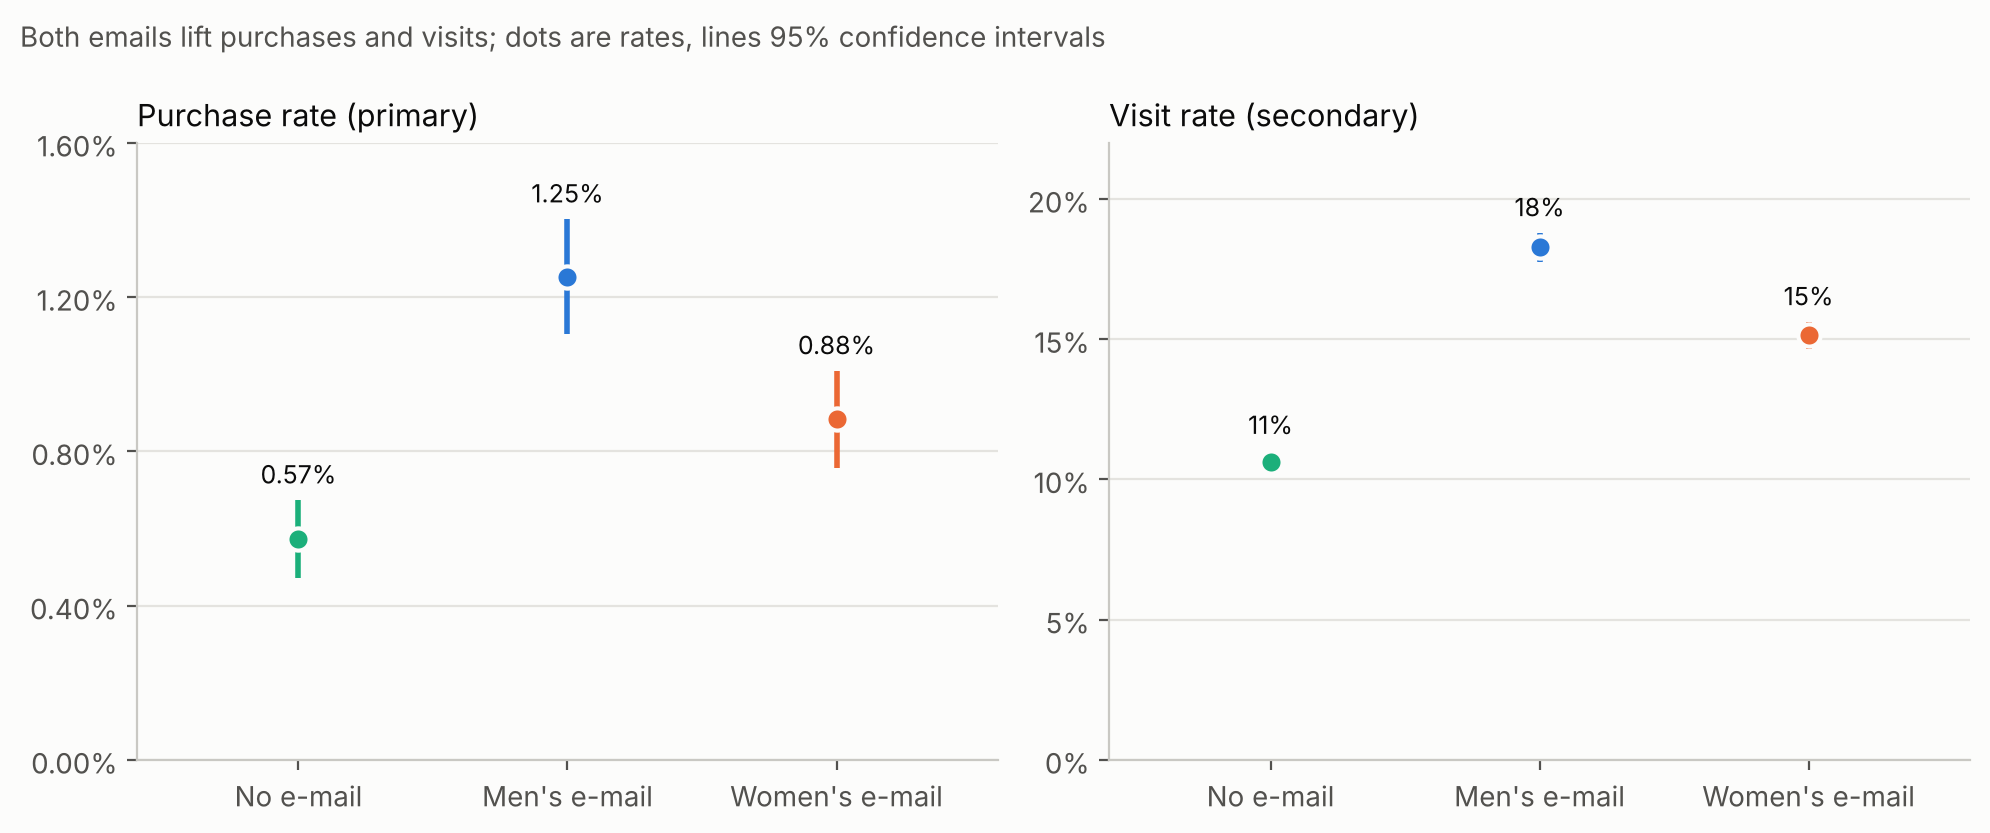

In [4]:
def plot_rates(ax, metric, title, fmt):
    for i, arm in enumerate(["control", "mens", "womens"]):
        g = groups[arm]
        p = g[metric].mean()
        se = np.sqrt(p * (1 - p) / len(g))
        ax.errorbar(i, p, yerr=1.96 * se, fmt="o", color=ARM_COLORS[arm], markersize=8,
                    capsize=0, elinewidth=2, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
        ax.annotate(fmt(p), (i, p + 1.96 * se), xytext=(0, 6), textcoords="offset points",
                    ha="center", color=INK, fontsize=9)
    ax.set_xticks(range(3), [ARM_LABELS[a] for a in ["control", "mens", "womens"]])
    ax.set_xlim(-0.6, 2.6)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt(v)))
    style_axes(ax, title=title)

fig, (ax1, ax2) = new_figure(10, 4.2, ncols=2)
plot_rates(ax1, "conversion", "Purchase rate (primary)", lambda v: f"{v:.2%}")
plot_rates(ax2, "visit", "Visit rate (secondary)", lambda v: f"{v:.0%}")
ax1.set_ylim(0, 0.016)
ax2.set_ylim(0, 0.22)
ax2.set_yticks(np.arange(0, 0.21, 0.05))
ax1.set_yticks(np.arange(0, 0.0161, 0.004))
fig.suptitle("Both emails lift purchases and visits; dots are rates, lines 95% confidence intervals",
             x=0.01, ha="left", color=INK_2, fontsize=10)
plt.tight_layout()
plt.show()

## 3. Secondary metric: visit rate

In [5]:
visit = comparison_table("visit")
visit[cols].style.format({
    "rate_control": "{:.2%}", "rate_treatment": "{:.2%}", "diff": "{:+.2%}", "diff_low": "{:+.2%}",
    "diff_high": "{:+.2%}", "lift": "{:+.0%}", "lift_low": "{:+.0%}", "lift_high": "{:+.0%}",
    "p_value": "{:.1e}", "p_holm": "{:.1e}",
})

,rate_control,rate_treatment,diff,diff_low,diff_high,lift,lift_low,lift_high,p_value,p_holm
Men's e-mail,10.62%,18.28%,+7.66%,+7.00%,+8.32%,+72%,+64%,+81%,5.7e-112,1.1e-111
Women's e-mail,10.62%,15.14%,+4.52%,+3.89%,+5.16%,+43%,+36%,+50%,3.2e-44,3.2e-44


Visits rise by 72% (men's) and 43% (women's). The relative lift on visits is *smaller* than on purchases, which is the opposite of what the metric tree in lesson 01 predicted. Section 5 looks at why.

## 4. Men's vs women's

In [6]:
m, w = groups["mens"], groups["womens"]
for metric in ["conversion", "visit"]:
    r = compare_proportions(m[metric].sum(), len(m), w[metric].sum(), len(w))
    print(f"{metric:>10}: men's minus women's = {r.diff:+.3%} (95% CI {r.diff_low:+.3%} to {r.diff_high:+.3%}), p = {r.p_value:.1e}")

conversion: men's minus women's = +0.369% (95% CI +0.174% to +0.564%), p = 2.1e-04
     visit: men's minus women's = +3.136% (95% CI +2.429% to +3.843%), p = 3.8e-18


The men's email beats the women's on both. This comparison was pre-registered as *secondary*, so it informs the choice between campaigns (decided on revenue in lesson 04) rather than standing as a confirmatory claim.

## 5. The conditional-metric trap: purchase rate among visitors

It is tempting to report "of the people who visited, how many bought?" for each group.

In [7]:
for arm, g in groups.items():
    print(f"{ARM_LABELS[arm]:>15}: {g['conversion'].sum() / g['visit'].sum():.2%} of visitors bought")

      No e-mail: 5.39% of visitors bought
   Men's e-mail: 6.86% of visitors bought
 Women's e-mail: 5.84% of visitors bought


Emailed visitors buy more often than holdout visitors. **But this is not a randomised comparison.** The email changes *who* visits: it brings back customers who would not have come otherwise, and they may be more or less ready to buy than the ones who come on their own. The groups of visitors are no longer alike, so a difference between them mixes the email's effect with a change in who is in the group.

Here both moved in the same direction, which is why visits rose less in relative terms than purchases: the extra visitors the email brought in were more likely to buy than the average visitor. It could easily have gone the other way: a catchy subject line could pull in many casual browsers and *lower* purchases per visitor while still adding purchases overall. That is why the design doc made this metric descriptive only, and why decisions rest on metrics computed over **all customers in each group**.

## 6. Verdict against the pre-registered rules

| Rule | Result |
|---|---|
| Validity checks | Passed (lesson 02) |
| Primary: purchase lift significant after Holm? | **Yes for both emails** (Holm p < 0.001 for each) |
| Secondary: visits | Up for both; consistent with the primary result |
| Men's vs women's | Men's higher on purchases and visits; the choice is made on revenue in lesson 04 |

Next, whether these extra purchases are worth enough money: [lesson 04](04_revenue.ipynb).

## Your turn

**a)** Recompute the women's email result with a plain Bonferroni correction (multiply each p-value by 2). Does anything change here? When would Holm and Bonferroni lead to different decisions?

**b)** The marketing lead wants to headline "the men's email increased purchases by 119%". Using the interval, write a more honest one-line headline.

**c)** Construct a small made-up example (numbers on paper are fine) where an email adds purchases overall but *lowers* the purchase rate among visitors.